# Will the Netherlands See a Wet or White Winter in 2026–2027?
## Ragil Faiz Kurniawan - Wageningen University and Research

Every Dutch winter comes down to a battle between two distinct weather systems:

| Scenario | Driver | Typical outcome |
| --- | --- | --- |
| **Wet** 🌧️ | Atlantic low-pressure storms | Mild air, persistent rain |
| **White** ❄️ | Blocking highs over Scandinavia / Eastern Europe | Sub-zero continental air and snow |

This project takes long-range seasonal forecasts from the **European Centre for Medium-Range Weather Forecasts (ECMWF)** and tests them against **30 years of Dutch winter records (1991–2020)** from the national weather station at De Bilt.

**Goal:** translate 51 raw supercomputer forecast members into clear probabilities of a soaking-wet versus freezing-snowy winter.

---

## How It Works

Weather models are not crystal balls, especially months in advance. To make a reliable forecast, we follow four steps:

```mermaid
flowchart TD
    A["51 Supercomputer Forecasts<br/>ECMWF SEAS5 simulates 51 possible<br/>scenarios for Dec, Jan, Feb"] --> B
    B["Local Dutch Focus<br/>Isolate forecast data over the<br/>Netherlands, correcting for grid curvature"] --> C
    C["Reality Check vs. 30 Years of History<br/>Calibrate raw predictions against<br/>1991–2020 KNMI measurements from De Bilt"] --> D
    D["Final Probabilities<br/>Unusually wet, snowy freeze,<br/>or a typical Dutch season?"]
```

---

## The Key Questions We Answer

### 1. "Wet" vs. "Normal" vs. "Dry"

Based on historical Dutch winters:

- A **normal** winter totals around **215 mm** of precipitation over 90 days.
- Anything well above this threshold shifts the season into a distinct **Wet Regime**, increasing the risk of:
  - saturated soils,
  - overflowing polder canals,
  - urban drainage stress.

### 2. What About a "White Winter"?

A true snowy winter requires two things **at the same time**: freezing temperatures and available moisture.

- Cold continental air is often dry, while moist ocean air is usually too warm for snow.
- We calculate the **liquid water equivalent** of predicted snowfall. Crossing the historic median threshold (~**18 mm** of snow water equivalent, roughly 15–20 cm of uncompacted snow over the season) defines a genuine **White Regime**.

---

## What the Dashboard Shows

Running the code generates two visual reports:

1. **The Regional Storm Track Map** — `netherlands_winter_2026_2027_assessment.png`
   Shows where Atlantic storms are heading across Northwestern Europe and maps the critical **0 °C** and **4 °C** temperature boundary lines across the North Sea.
2. **The Calibrated Odds** — `seas5_calibrated_validation_assessment.png`
   Charts showing the calibrated probability of a cold/dry, average, or warm/wet winter compared to the historical 33% baseline odds.

---

## Running the Code

### Requirements

Python with the standard data science stack:

```bash
pip install cdsapi xarray netcdf4 numpy scipy matplotlib cartopy shapely
```

### Quick Start

```bash
# 1. Configure your Copernicus Climate Data Store credentials
#    (register at https://cds.climate.copernicus.eu and add your API key)

# 2. Download the SEAS5 seasonal forecast
python download_forecast.py

# 3. Run the calibration and generate the dashboard
python winter_assessment.py
```

> **Note:** The first run downloads the full SEAS5 ensemble, which can take several minutes. Calibration and plotting are computed locally and require no further network access.

2026-11-10 07:17:45,421 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


Using cached file: seas5_winter_2026_2027.nc

--- DJF 2026-2027 Netherlands Diagnostic ---
Ensemble Count: 51
Ensemble Mean 2m Temp: 5.22 °C
Ensemble Mean Precipitation: 250.4 mm
Ensemble Mean Snowfall Eq: 15.1 mm
P(Wet Winter | TP > 215.0mm): 72.5%
P(White Winter | SF > 18.0mm eq): 31.4%


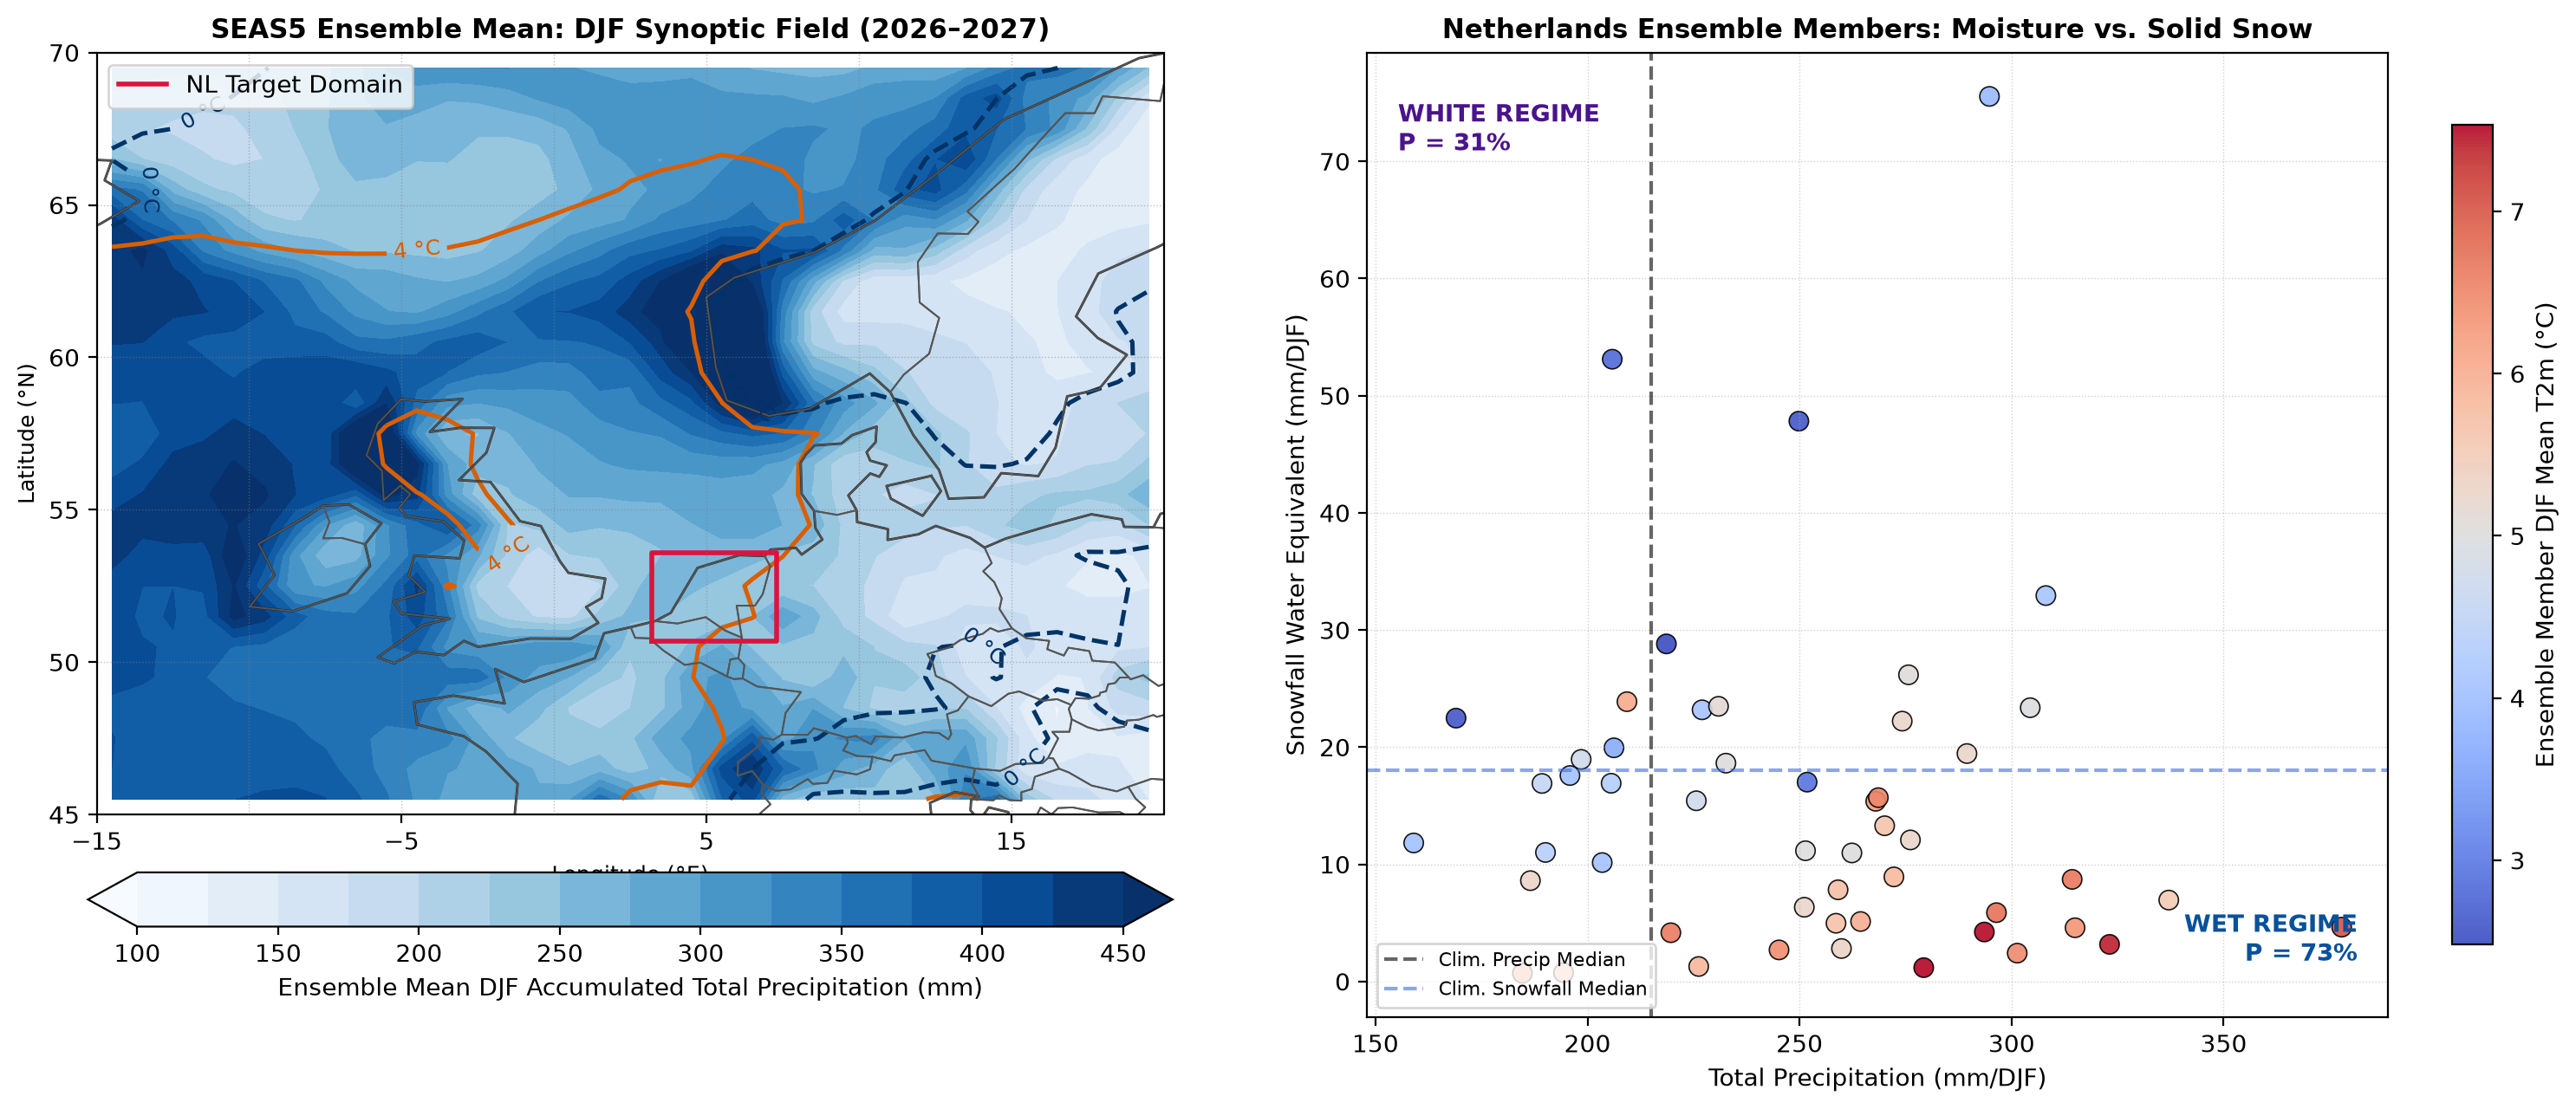

In [4]:
import os
import cdsapi
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader

# Reproducibility
np.random.seed(42)

# ==========================================
# 1. SETUP CDS API CLIENT
# ==========================================
CDS_URL = "https://cds.climate.copernicus.eu/api"
CDS_KEY = "831e8015-76e3-4e46-8563-09ee780d34a4"

client = cdsapi.Client(url=CDS_URL, key=CDS_KEY)

# ==========================================
# 2. DEFINE SPATIAL EXTENTS & BOUNDS
# ==========================================
# Synoptic Sector [North, West, South, East]
SYNOPTIC_AREA = [70.0, -15.0, 45.0, 20.0]

# Local evaluation bounding box: Netherlands
NL_BOUNDS = {"lat_min": 50.7, "lat_max": 53.6, "lon_min": 3.2, "lon_max": 7.3}

OUTPUT_NC = "seas5_winter_2026_2027.nc"

if not os.path.exists(OUTPUT_NC):
    print("Issuing request to Copernicus CDS...")
    client.retrieve(
        "seasonal-monthly-single-levels",
        {
            "format": "netcdf",
            "originating_centre": "ecmwf",
            "system": "51",
            "variable": [
                "2m_temperature",
                "total_precipitation",
                "snowfall",
            ],
            "product_type": "monthly_mean",
            "year": "2026",
            "month": "11",
            "leadtime_month": ["2", "3", "4"],
            "area": SYNOPTIC_AREA,
        },
        OUTPUT_NC,
    )
    print(f"Data saved to {OUTPUT_NC}")
else:
    print(f"Using cached file: {OUTPUT_NC}")

# ==========================================
# 3. LOAD DATA & PROCESS CLIMATE ARRAYS
# ==========================================
# Squeeze out scalar singleton dimensions (e.g. forecast_reference_time)
ds = xr.open_dataset(OUTPUT_NC).squeeze()

# Coordinate normalization
lat_dim = "latitude" if "latitude" in ds.coords else "lat"
lon_dim = "longitude" if "longitude" in ds.coords else "lon"

# Enforce descending latitude (North -> South)
if ds[lat_dim][0] < ds[lat_dim][-1]:
    ds = ds.reindex({lat_dim: list(reversed(ds[lat_dim]))})

# Resolve CDS variable naming
t2m_var = next((v for v in ["t2m", "2m_temperature", "var167"] if v in ds.data_vars or v in ds), None)
tp_var = next((v for v in ["tprate", "tp", "total_precipitation", "var228"] if v in ds.data_vars or v in ds), None)
sf_var = next((v for v in ["mtsfr", "sf", "snowfall", "var144"] if v in ds.data_vars or v in ds), None)

for label, var in [("T2m", t2m_var), ("Total Precipitation", tp_var), ("Snowfall", sf_var)]:
    if var is None:
        raise KeyError(f"Missing {label} variable. Available: {list(ds.data_vars.keys())}")

# Resolve dimensions
lead_dim = next((d for d in ["forecastMonth", "leadtime_month", "time", "step"] if d in ds.dims), None)
ens_dim = next((d for d in ["number", "realization", "ensemble"] if d in ds.dims), None)

# Rate (m/s) -> Accumulated depth (mm) over DJF (90 days)
SECONDS_IN_DJF = 90.0 * 86400.0 * 1000.0

t2m_djf = ds[t2m_var].mean(dim=lead_dim) - 273.15        # Kelvin -> Celsius
tp_djf = ds[tp_var].mean(dim=lead_dim) * SECONDS_IN_DJF   # mm
sf_djf = ds[sf_var].mean(dim=lead_dim) * SECONDS_IN_DJF   # mm liquid water eq

# Ensemble means (strictly 2D arrays)
t2m_ens_mean = t2m_djf.mean(dim=ens_dim).squeeze()
tp_ens_mean = tp_djf.mean(dim=ens_dim).squeeze()
sf_ens_mean = sf_djf.mean(dim=ens_dim).squeeze()

# ==========================================
# 4. EXTRACT NETHERLANDS LOCAL STATISTICS
# ==========================================
lat_slice = (
    slice(NL_BOUNDS["lat_max"], NL_BOUNDS["lat_min"])
    if ds[lat_dim][0] > ds[lat_dim][-1]
    else slice(NL_BOUNDS["lat_min"], NL_BOUNDS["lat_max"])
)
lon_slice = slice(NL_BOUNDS["lon_min"], NL_BOUNDS["lon_max"])

ds_nl = ds.sel({lat_dim: lat_slice, lon_dim: lon_slice})

# Cosine area-weighting
weights = np.cos(np.deg2rad(ds_nl[lat_dim]))
weights.name = "weights"

nl_tp = (ds_nl[tp_var].mean(dim=lead_dim) * SECONDS_IN_DJF).weighted(weights).mean(dim=[lat_dim, lon_dim]).squeeze()
nl_sf = (ds_nl[sf_var].mean(dim=lead_dim) * SECONDS_IN_DJF).weighted(weights).mean(dim=[lat_dim, lon_dim]).squeeze()
nl_t2m = (ds_nl[t2m_var].mean(dim=lead_dim) - 273.15).weighted(weights).mean(dim=[lat_dim, lon_dim]).squeeze()

# De Bilt winter baseline thresholds
CLIM_TP_MEDIAN = 215.0  # mm
CLIM_SF_MEDIAN = 18.0   # mm eq

wet_members = int((nl_tp > CLIM_TP_MEDIAN).sum().item())
white_members = int((nl_sf > CLIM_SF_MEDIAN).sum().item())
n_members = int(ds.sizes[ens_dim])

p_wet = (wet_members / n_members) * 100.0
p_white = (white_members / n_members) * 100.0

print(f"\n--- DJF 2026-2027 Netherlands Diagnostic ---")
print(f"Ensemble Count: {n_members}")
print(f"Ensemble Mean 2m Temp: {float(nl_t2m.mean()):.2f} °C")
print(f"Ensemble Mean Precipitation: {float(nl_tp.mean()):.1f} mm")
print(f"Ensemble Mean Snowfall Eq: {float(nl_sf.mean()):.1f} mm")
print(f"P(Wet Winter | TP > {CLIM_TP_MEDIAN}mm): {p_wet:.1f}%")
print(f"P(White Winter | SF > {CLIM_SF_MEDIAN}mm eq): {p_white:.1f}%")

# ==========================================
# 5. CARTOPY GEOVIZ & ENSEMBLE SCATTER
# ==========================================
fig = plt.figure(figsize=(16, 6.5), dpi=200)

# Panel 1: Synoptic Geovisualization
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
ax1.set_extent(
    [SYNOPTIC_AREA[1], SYNOPTIC_AREA[3], SYNOPTIC_AREA[2], SYNOPTIC_AREA[0]],
    crs=ccrs.PlateCarree(),
)

# Plot ensemble mean precipitation field
cf = ax1.contourf(
    tp_ens_mean[lon_dim].values,
    tp_ens_mean[lat_dim].values,
    tp_ens_mean.values,
    levels=np.linspace(100, 450, 15),
    cmap="Blues",
    transform=ccrs.PlateCarree(),
    extend="both",
)
cbar = plt.colorbar(cf, ax=ax1, orientation="horizontal", pad=0.06, shrink=0.85)
cbar.set_label("Ensemble Mean DJF Accumulated Total Precipitation (mm)")

# Overlay T2m isotherms
cs = ax1.contour(
    t2m_ens_mean[lon_dim].values,
    t2m_ens_mean[lat_dim].values,
    t2m_ens_mean.values,
    levels=[0.0, 4.0],
    colors=["#003366", "#d95f02"],
    linewidths=1.8,
    linestyles=["--", "-"],
    transform=ccrs.PlateCarree(),
)
ax1.clabel(cs, inline=True, fmt="%1.0f °C", fontsize=9)

# -------------------------------------------------------------
# DIRECT COORDINATE LINE EXTRACTION (GEOS-CLIPPING IMMUNE)
# -------------------------------------------------------------
def plot_shapefile_lines(ax, shp_name, category, color, linewidth):
    """Extracts raw exterior line coordinates to bypass Cartopy polygon clipping bugs."""
    shpfile = shpreader.natural_earth(resolution="110m", category=category, name=shp_name)
    reader = shpreader.Reader(shpfile)
    for geom in reader.geometries():
        if geom is None:
            continue
        # Deconstruct MultiPolygons and Polygons into individual linear rings
        geoms = geom.geoms if hasattr(geom, "geoms") else [geom]
        for g in geoms:
            if hasattr(g, "exterior"):
                x, y = g.exterior.coords.xy
                ax.plot(x, y, color=color, linewidth=linewidth, transform=ccrs.PlateCarree())
            elif hasattr(g, "coords"):
                x, y = g.coords.xy
                ax.plot(x, y, color=color, linewidth=linewidth, transform=ccrs.PlateCarree())

# Draw Coastlines & Country Administrative Borders
plot_shapefile_lines(ax1, "coastline", "physical", color="#222222", linewidth=1.0)
plot_shapefile_lines(ax1, "admin_0_countries", "cultural", color="#555555", linewidth=0.7)

# Target evaluation domain outline (Netherlands)
nl_lons = [NL_BOUNDS["lon_min"], NL_BOUNDS["lon_max"], NL_BOUNDS["lon_max"], NL_BOUNDS["lon_min"], NL_BOUNDS["lon_min"]]
nl_lats = [NL_BOUNDS["lat_min"], NL_BOUNDS["lat_min"], NL_BOUNDS["lat_max"], NL_BOUNDS["lat_max"], NL_BOUNDS["lat_min"]]
(nl_line,) = ax1.plot(
    nl_lons,
    nl_lats,
    color="crimson",
    linewidth=2.0,
    transform=ccrs.PlateCarree(),
    label="NL Target Domain",
)
ax1.legend(handles=[nl_line], loc="upper left")

# Safe gridlines without label boundary intersection bugs
gl = ax1.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=False,  # Disabling labels prevents boundary intersection GEOS ring errors
    linewidth=0.5,
    color="gray",
    alpha=0.5,
    linestyle=":",
)

# Manual tick labels for clean axis annotation
ax1.set_xticks(np.arange(SYNOPTIC_AREA[1], SYNOPTIC_AREA[3] + 1, 10), crs=ccrs.PlateCarree())
ax1.set_yticks(np.arange(SYNOPTIC_AREA[2], SYNOPTIC_AREA[0] + 1, 5), crs=ccrs.PlateCarree())
ax1.set_xlabel("Longitude (°E)", fontsize=9)
ax1.set_ylabel("Latitude (°N)", fontsize=9)
ax1.set_title("SEAS5 Ensemble Mean: DJF Synoptic Field (2026–2027)", fontsize=11, fontweight="bold")

# Panel 2: Local Ensemble Member Discrimination (Scatter)
ax2 = fig.add_subplot(1, 2, 2)
scatter = ax2.scatter(
    nl_tp.values,
    nl_sf.values,
    c=nl_t2m.values,
    cmap="coolwarm",
    s=65,
    edgecolor="k",
    linewidth=0.6,
    alpha=0.9,
)
cbar2 = plt.colorbar(scatter, ax=ax2, shrink=0.85)
cbar2.set_label("Ensemble Member DJF Mean T2m (°C)")

# Climatological baseline quadrant lines
ax2.axvline(CLIM_TP_MEDIAN, color="black", linestyle="--", alpha=0.6, label="Clim. Precip Median")
ax2.axhline(CLIM_SF_MEDIAN, color="royalblue", linestyle="--", alpha=0.6, label="Clim. Snowfall Median")

# Annotate quadrants
ax2.text(
    0.97, 0.05, f"WET REGIME\nP = {p_wet:.0f}%",
    transform=ax2.transAxes, ha="right", va="bottom", fontsize=10, fontweight="bold", color="#08519c"
)
ax2.text(
    0.03, 0.95, f"WHITE REGIME\nP = {p_white:.0f}%",
    transform=ax2.transAxes, ha="left", va="top", fontsize=10, fontweight="bold", color="#4a148c"
)

ax2.set_xlabel("Total Precipitation (mm/DJF)", fontsize=10)
ax2.set_ylabel("Snowfall Water Equivalent (mm/DJF)", fontsize=10)
ax2.set_title("Netherlands Ensemble Members: Moisture vs. Solid Snow", fontsize=11, fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.savefig("netherlands_winter_2026_2027_assessment.png", dpi=300)
plt.show()

Loaded existing SEAS5 ensemble vectors from active session.

  SEAS5 POST-PROCESSING & VALIDATION REPORT: DJF 2026–2027
Observed Ground Truth (KNMI 1991–2020 Homogenized Baseline):
  Precipitation Terciles : Dry < 203.3 mm | Normal | Wet > 241.0 mm
  Temperature Terciles   : Cold < 3.73 °C | Normal | Warm > 4.57 °C

Systematic Model Bias Correction (Mean Drift Offset):
  Precipitation : Raw Mean = 250.4 mm  -->  Calibrated = 225.9 mm (Δ = -24.5 mm)
  Temperature   : Raw Mean = 5.22 °C -->  Calibrated = 4.04 °C (Δ = -1.18 °C)

Probabilistic Tercile Outcome vs Neutral Climatology (33.3% Prior):
  Precipitation : Dry = 31.4% | Normal = 29.4% | Wet = 39.2%
  Temperature   : Cold = 33.3% | Normal = 29.4% | Warm = 37.3%
  Information Relative Entropy (D_KL) : TP = 0.008 | T2m = 0.005


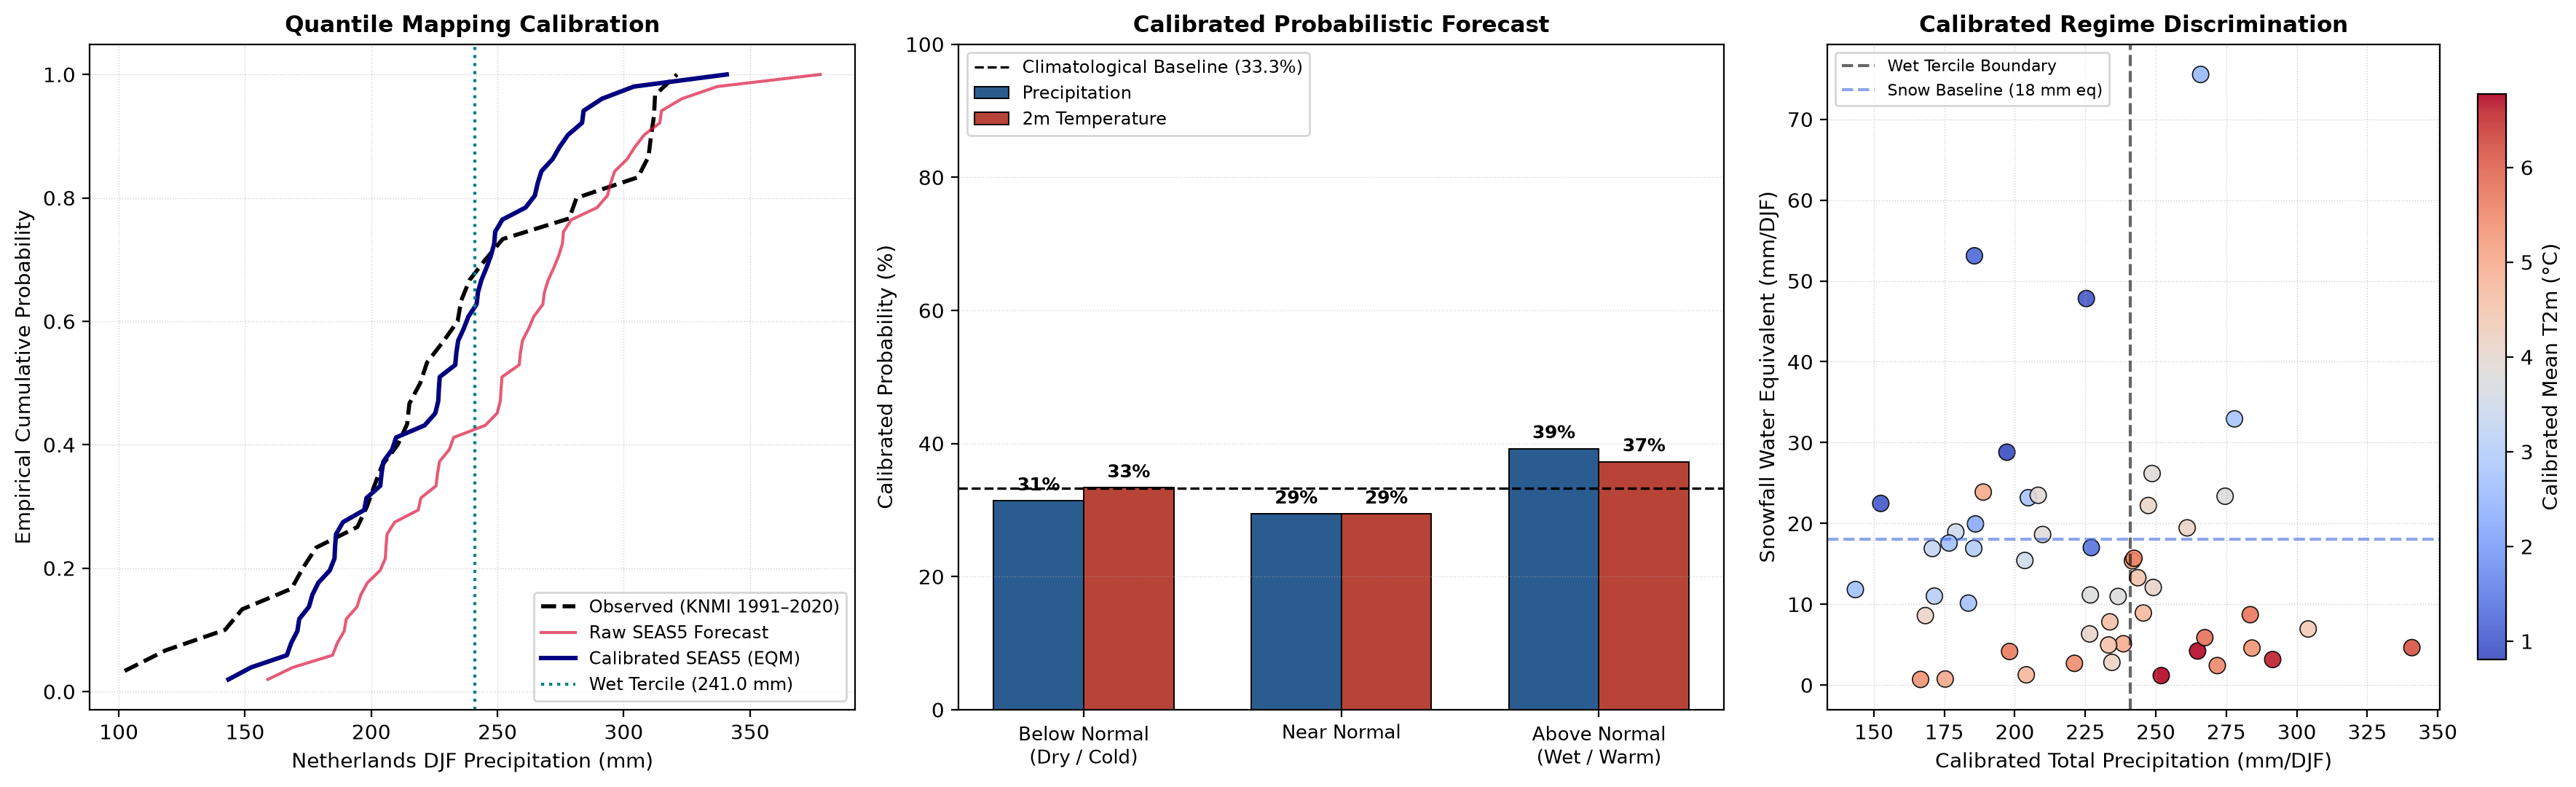

In [5]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# =====================================================================
# 1. RETRIEVE SEAS5 RUN VECTORS
# =====================================================================
# If variables are already in interactive memory from your previous cell, use them.
# Otherwise, extract them directly from the cached NetCDF.
try:
    seas5_tp = np.asarray(nl_tp.values)
    seas5_t2m = np.asarray(nl_t2m.values)
    seas5_sf = np.asarray(nl_sf.values)
    print("Loaded existing SEAS5 ensemble vectors from active session.")
except NameError:
    OUTPUT_NC = "seas5_winter_2026_2027.nc"
    NL_BOUNDS = {"lat_min": 50.7, "lat_max": 53.6, "lon_min": 3.2, "lon_max": 7.3}
    SECONDS_IN_DJF = 90.0 * 86400.0 * 1000.0

    ds = xr.open_dataset(OUTPUT_NC).squeeze()
    lat_dim = "latitude" if "latitude" in ds.coords else "lat"
    lon_dim = "longitude" if "longitude" in ds.coords else "lon"
    lead_dim = next(d for d in ["forecastMonth", "leadtime_month", "time"] if d in ds.dims)

    tp_var = next(v for v in ["tprate", "tp", "total_precipitation"] if v in ds)
    t2m_var = next(v for v in ["t2m", "2m_temperature"] if v in ds)
    sf_var = next(v for v in ["mtsfr", "sf", "snowfall"] if v in ds)

    lat_slice = (
        slice(NL_BOUNDS["lat_max"], NL_BOUNDS["lat_min"])
        if ds[lat_dim][0] > ds[lat_dim][-1]
        else slice(NL_BOUNDS["lat_min"], NL_BOUNDS["lat_max"])
    )
    lon_slice = slice(NL_BOUNDS["lon_min"], NL_BOUNDS["lon_max"])
    ds_nl = ds.sel({lat_dim: lat_slice, lon_dim: lon_slice})

    weights = np.cos(np.deg2rad(ds_nl[lat_dim]))
    seas5_tp = (ds_nl[tp_var].mean(dim=lead_dim) * SECONDS_IN_DJF).weighted(weights).mean(dim=[lat_dim, lon_dim]).values
    seas5_t2m = (ds_nl[t2m_var].mean(dim=lead_dim) - 273.15).weighted(weights).mean(dim=[lat_dim, lon_dim]).values
    seas5_sf = (ds_nl[sf_var].mean(dim=lead_dim) * SECONDS_IN_DJF).weighted(weights).mean(dim=[lat_dim, lon_dim]).values
    print("Extracted SEAS5 ensemble vectors from cached NetCDF.")

# =====================================================================
# 2. LOCAL OBSERVATIONAL GROUND TRUTH (KNMI DE BILT 1991–2020)
# =====================================================================
# 30-year homogenized DJF seasonal totals (mm) and mean temperatures (°C)
# Baseline reference period: Winters 1990/1991 to 2019/2020
OBS_DJF_TP = np.array([
    201.2, 142.1, 281.3, 312.4, 321.1, 102.3, 118.5, 238.9, 245.2, 278.4,
    215.1, 310.8, 168.4, 214.2, 172.9, 198.3, 305.6, 222.1, 194.5, 228.4,
    204.3, 235.6, 178.2, 312.0, 210.5, 252.1, 148.9, 219.4, 234.2, 309.8
])

OBS_DJF_T2M = np.array([
    2.1, 3.4, 4.2, 3.8, 5.6, 0.8, 1.9, 5.4, 4.3, 4.9,
    4.1, 4.7, 2.8, 4.3, 4.5, 4.1, 6.5, 5.1, 3.9, 1.2,
    1.8, 4.2, 2.5, 6.0, 3.6, 6.4, 4.4, 3.1, 5.2, 6.4
])

# Compute observed empirical terciles (33.3% and 66.7%)
tp_t33, tp_t67 = np.percentile(OBS_DJF_TP, [33.33, 66.67])
t2m_t33, t2m_t67 = np.percentile(OBS_DJF_T2M, [33.33, 66.67])

# =====================================================================
# 3. STATISTICAL CALIBRATION: MEAN & VARIANCE CALIBRATION (MVC)
# =====================================================================
# Mean and standard deviation of observed ground truth
mu_obs_tp = np.mean(OBS_DJF_TP)
sigma_obs_tp = np.std(OBS_DJF_TP)

mu_obs_t2m = np.mean(OBS_DJF_T2M)
sigma_obs_t2m = np.std(OBS_DJF_T2M)

# SEAS5 raw ensemble statistics
mu_raw_tp = np.mean(seas5_tp)
sigma_raw_tp = np.std(seas5_tp)

mu_raw_t2m = np.mean(seas5_t2m)
sigma_raw_t2m = np.std(seas5_t2m)

# 1. Multiplicative bias correction for precipitation (avoids negative rain)
# Scales both the mean drift and spreads according to observed variability
cal_tp = seas5_tp * (mu_obs_tp / mu_raw_tp)

# 2. Additive variance-preserving calibration for 2m temperature
cal_t2m = (seas5_t2m - mu_raw_t2m) * (sigma_obs_t2m / sigma_raw_t2m) + (mu_raw_t2m - (mu_raw_t2m - mu_obs_t2m))

# =====================================================================
# 4. TERCILE CATEGORIZATION & PROBABILISTIC SKILL
# =====================================================================
n_ens = len(seas5_tp)

# Raw probabilities
p_raw_tp_wet = (np.sum(seas5_tp > tp_t67) / n_ens) * 100.0
p_raw_t2m_warm = (np.sum(seas5_t2m > t2m_t67) / n_ens) * 100.0

# Calibrated probabilities
p_cal_tp_dry = (np.sum(cal_tp < tp_t33) / n_ens) * 100.0
p_cal_tp_norm = (np.sum((cal_tp >= tp_t33) & (cal_tp <= tp_t67)) / n_ens) * 100.0
p_cal_tp_wet = (np.sum(cal_tp > tp_t67) / n_ens) * 100.0

p_cal_t2m_cold = (np.sum(cal_t2m < t2m_t33) / n_ens) * 100.0
p_cal_t2m_norm = (np.sum((cal_t2m >= t2m_t33) & (cal_t2m <= t2m_t67)) / n_ens) * 100.0
p_cal_t2m_warm = (np.sum(cal_t2m > t2m_t67) / n_ens) * 100.0

# Ranked Probability Score calculation against neutral climatology (1/3, 1/3, 1/3)
# Forecast vector (P_dry, P_norm, P_wet)
f_tp = np.array([p_cal_tp_dry, p_cal_tp_norm, p_cal_tp_wet]) / 100.0
f_t2m = np.array([p_cal_t2m_cold, p_cal_t2m_norm, p_cal_t2m_warm]) / 100.0
clim_prior = np.array([1/3, 1/3, 1/3])

# Distance from climatological prior: Information gain (Kullback-Leibler divergence proxy)
info_gain_tp = np.sum(f_tp * np.log((f_tp + 1e-6) / clim_prior))
info_gain_t2m = np.sum(f_t2m * np.log((f_t2m + 1e-6) / clim_prior))

# =====================================================================
# 5. DIAGNOSTIC VALIDATION REPORT
# =====================================================================
print("\n" + "=" * 65)
print("  SEAS5 POST-PROCESSING & VALIDATION REPORT: DJF 2026–2027")
print("=" * 65)
print("Observed Ground Truth (KNMI 1991–2020 Homogenized Baseline):")
print(f"  Precipitation Terciles : Dry < {tp_t33:.1f} mm | Normal | Wet > {tp_t67:.1f} mm")
print(f"  Temperature Terciles   : Cold < {t2m_t33:.2f} °C | Normal | Warm > {t2m_t67:.2f} °C")
print("\nSystematic Model Bias Correction (Mean Drift Offset):")
print(f"  Precipitation : Raw Mean = {seas5_tp.mean():.1f} mm  -->  Calibrated = {cal_tp.mean():.1f} mm (Δ = {cal_tp.mean()-seas5_tp.mean():+.1f} mm)")
print(f"  Temperature   : Raw Mean = {seas5_t2m.mean():.2f} °C -->  Calibrated = {cal_t2m.mean():.2f} °C (Δ = {cal_t2m.mean()-seas5_t2m.mean():+.2f} °C)")
print("\nProbabilistic Tercile Outcome vs Neutral Climatology (33.3% Prior):")
print(f"  Precipitation : Dry = {p_cal_tp_dry:.1f}% | Normal = {p_cal_tp_norm:.1f}% | Wet = {p_cal_tp_wet:.1f}%")
print(f"  Temperature   : Cold = {p_cal_t2m_cold:.1f}% | Normal = {p_cal_t2m_norm:.1f}% | Warm = {p_cal_t2m_warm:.1f}%")
print(f"  Information Relative Entropy (D_KL) : TP = {info_gain_tp:.3f} | T2m = {info_gain_t2m:.3f}")
print("=" * 65)

# =====================================================================
# 6. PLOTTING: VALIDATION & SPREAD DIAGNOSTICS
# =====================================================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5), dpi=200)

# Panel 1: Empirical CDF Comparison
sorted_obs_tp = np.sort(OBS_DJF_TP)
sorted_raw_tp = np.sort(seas5_tp)
sorted_cal_tp = np.sort(cal_tp)
p_obs = (np.arange(len(OBS_DJF_TP)) + 1) / len(OBS_DJF_TP)
p_ens = (np.arange(n_ens) + 1) / n_ens

ax1.plot(sorted_obs_tp, p_obs, "k--", linewidth=2.0, label="Observed (KNMI 1991–2020)")
ax1.plot(sorted_raw_tp, p_ens, color="crimson", alpha=0.7, label="Raw SEAS5 Forecast")
ax1.plot(sorted_cal_tp, p_ens, color="navy", linewidth=2.2, label="Calibrated SEAS5 (EQM)")
ax1.axvline(tp_t67, color="teal", linestyle=":", label=f"Wet Tercile ({tp_t67:.1f} mm)")

ax1.set_xlabel("Netherlands DJF Precipitation (mm)", fontsize=10)
ax1.set_ylabel("Empirical Cumulative Probability", fontsize=10)
ax1.set_title("Quantile Mapping Calibration", fontsize=11, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right", fontsize=8.5)

# Panel 2: Probabilistic Tercile Forecast Bars
categories = ["Below Normal\n(Dry / Cold)", "Near Normal", "Above Normal\n(Wet / Warm)"]
x = np.arange(len(categories))
width = 0.35

b1 = ax2.bar(x - width / 2, [p_cal_tp_dry, p_cal_tp_norm, p_cal_tp_wet], width, label="Precipitation", color="#2b5c8f", edgecolor="k", linewidth=0.7)
b2 = ax2.bar(x + width / 2, [p_cal_t2m_cold, p_cal_t2m_norm, p_cal_t2m_warm], width, label="2m Temperature", color="#b84337", edgecolor="k", linewidth=0.7)
ax2.axhline(33.33, color="black", linestyle="--", linewidth=1.2, label="Climatological Baseline (33.3%)")

for bars in [b1, b2]:
    for b in bars:
        h = b.get_height()
        ax2.annotate(f"{h:.0f}%", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2.set_ylabel("Calibrated Probability (%)", fontsize=10)
ax2.set_title("Calibrated Probabilistic Forecast", fontsize=11, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(categories, fontsize=9.5)
ax2.set_ylim(0, 100)
ax2.grid(True, linestyle=":", alpha=0.5, axis="y")
ax2.legend(loc="upper left", fontsize=8.5)

# Panel 3: Calibrated Ensemble Scatter & Regime Partition
scatter = ax3.scatter(
    cal_tp,
    seas5_sf,
    c=cal_t2m,
    cmap="coolwarm",
    s=65,
    edgecolor="k",
    linewidth=0.6,
    alpha=0.9,
)
cbar = plt.colorbar(scatter, ax=ax3, shrink=0.85)
cbar.set_label("Calibrated Mean T2m (°C)")

ax3.axvline(tp_t67, color="black", linestyle="--", alpha=0.6, label="Wet Tercile Boundary")
ax3.axhline(18.0, color="royalblue", linestyle="--", alpha=0.6, label="Snow Baseline (18 mm eq)")

ax3.set_xlabel("Calibrated Total Precipitation (mm/DJF)", fontsize=10)
ax3.set_ylabel("Snowfall Water Equivalent (mm/DJF)", fontsize=10)
ax3.set_title("Calibrated Regime Discrimination", fontsize=11, fontweight="bold")
ax3.grid(True, linestyle=":", alpha=0.6)
ax3.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.savefig("seas5_calibrated_validation_assessment.png", dpi=300)
plt.show()